<a href="https://colab.research.google.com/github/PalQuisp/Sis420-int/blob/main/neumonia_08_metricas_clasificacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sensioai/blog/blob/master/016_metricas_clasificacion/metricas_clasficacion.ipynb)

# Métricas para Clasificación Binaria

En [posts](https://sensioai.com/blog/015_logistic_regression) anteriores hemos visto como podemos implementar modelos lineales para clasficación binaria, ejemplos de los modelos más simples en el `Machine Learning` pero no por ello menos usados (pese a las limitaciones que ya hemos comentado, estos modelos son eficientes y explicables, lo cual es preferido en multitud de aplicaciones). En este post vamos a ver algunas de las métricas más utilizadas en clasificación binaria (aunque pueden extenderse también a clasificación en varias clases). Estas métricas nos van a ser muy útiles para caracterizar el desempeño de nuestros modelos y comparar diferentes modelos entre sí para, por ejemplos, utilizar el mejor.

## El dataset MNIST

En los posts anteriores sobre clasificación binaria hemos trabajado con el dataset Iris para clasificación de flores a partir de características como el ancho o la longitud de sus pétalos. En este post vamos a utilizar un nuevo dataset, probablemente el más utilizado mientras aprendemos sobre `Deep Learning` y considerado el *hello world* del `Machine Learning`: el dataset [MNIST](http://yann.lecun.com/exdb/mnist/). Este dataset fue elaborado con el objetivo de entrenar modelos automáticos de OCR (*Optical Character Recognition*) para poder acelerar el trabajo de clasificación de correo a partir del código postal escrito. Está formado por 70,0000 imágenes de dígitos manuscritos, entre $0$ y $9$, y el objetivo es el de ser capaces de diseñar un algoritmo capaz de clasificar una imágen (decir que número es) directamente a partir de sus pixeles. De entre las diferentes fuentes que podemos utilizar para descargar estos datos, vamos a utilizar [Scikit-Learn](https://scikit-learn.org/stable/).

In [ ]:
from sklearn.datasets import fetch_openml

import numpy as np
from sklearn.model_selection import train_test_split

from google.colab import drive
drive.mount("/content/drive")


# 1. Cargar el archivo .npz

data = np.load('/content/drive/MyDrive/machine learning/laboratorio/pneumoniamnist.npz')

# 2. Extraer los datos usando las claves reales de tu archivo
X_train_raw = data['train_images']
y_train = data['train_labels']

X_test_raw = data['test_images']
y_test = data['test_labels']

# 3. Aplanar las imágenes (reshape) para el Perceptrón
# Convierte dimensiones como (N, 28, 28) a (N, 784)
X_train = X_train_raw.reshape(X_train_raw.shape[0], -1)
X_test = X_test_raw.reshape(X_test_raw.shape[0], -1)

# 4. Escalamiento [0, 1]
X_train = X_train / 255.0  # o X_train / np.max(X_train)
X_test = X_test / 255.0

print("Forma de X_train:", X_train.shape)
print("Forma de y_train:", y_train.shape)



#mnist = fetch_openml('mnist_784', version=1)
#mnist.keys()

Mounted at /content/drive
Forma de X_train: (3882, 784)
Forma de y_train: (3882, 1)


In [ ]:
# Reemplazo de: X, y = mnist["data"], mnist["target"]
X = data['train_images']
y = data['train_labels']

X.shape, y.shape

((3882, 28, 28), (3882, 1))

Como puedes ver, cada imágen está formada por $784$ características (los pixeles). Podemos visualizar unas cuantas imágenes junto a sus etiquetas de la siguiente manera para hacernos una idea del tipo de datos al que nos enfrentamos.

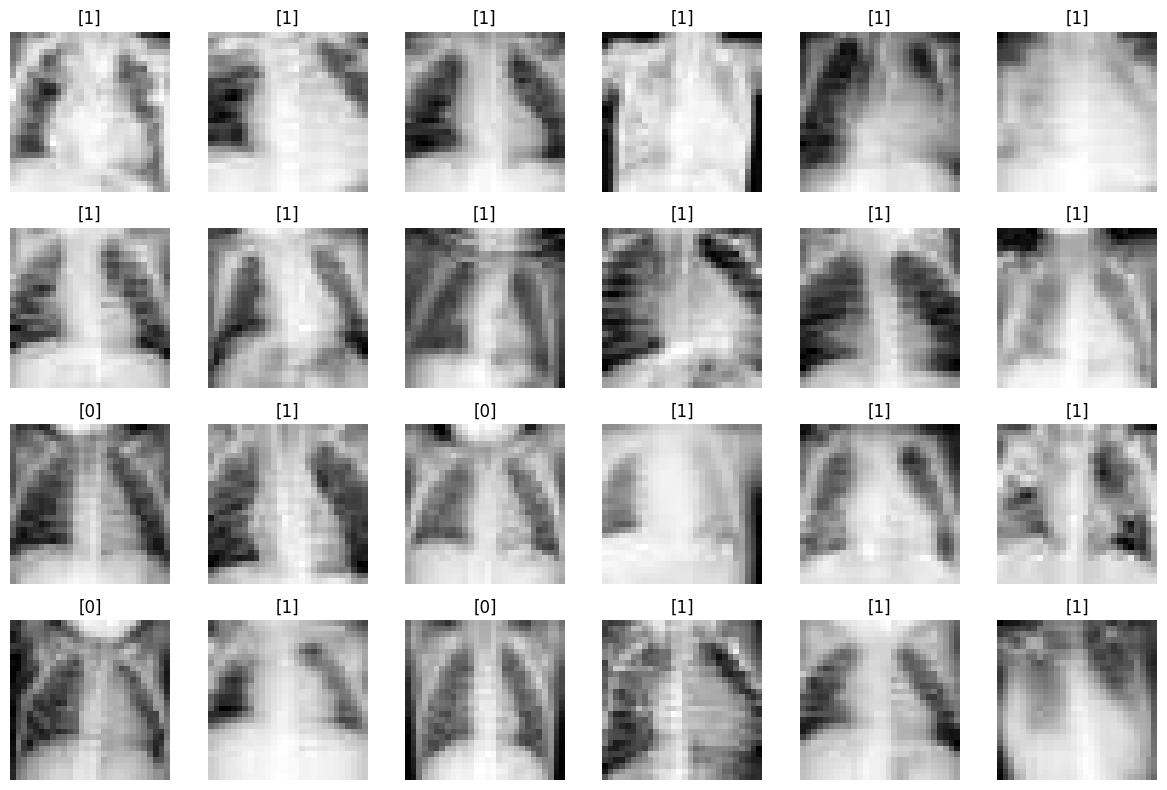

In [ ]:
 %matplotlib inline
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import random

r, c = 4, 6
fig = plt.figure(figsize=(2*c, 2*r))

for _r in range(r):
    for _c in range(c):
        plt.subplot(r, c, _r*c + _c + 1)

        # Selección aleatoria usando NumPy
        ix = random.randint(0, len(data['train_images']) - 1)
        img = data['train_images'][ix]

        plt.imshow(img, cmap='gray')
        plt.axis("off")
        plt.title(data['train_labels'][ix])

plt.tight_layout()
plt.show()

Por último, vamos a extraer $60,000$ imágenes para entrenar nuestro modelo y $10,000$ para evaluarlo y calcular las diferentes métricas que veremos.

In [ ]:
#X_train, X_test, y_train, y_test = X[:60000] / 255., X[60000:] / 255., y[:60000], y[60000:]

X_train, X_test, y_train, y_test = (
    data['train_images'].reshape(len(data['train_images']), -1) / 255.0,
    data['test_images'].reshape(len(data['test_images']), -1) / 255.0,
    data['train_labels'],
    data['test_labels']
)

> 💡 Recuerda que para que nuestro modelo pueda aprender mejor tenemos que normalizar los datos que usaremos como entrada. En este caso cada píxel está representado por un valor entero entre 0-255, por lo que al dividir cada imágen por 255 nos aseguramos que nuestros valores a la entrada estén en el rango 0-1

## Entrenando un clasificador binario

Para llevar a cabo una tarea de clasificación binaria necesitamos que nuestro dataset esté dividido en dos clases, sin embargo el dataset MNIST, cómo ya hemos visto, tiene $10$ clases (todos los dígitos entre $0$ y $9$). En este caso vamos entrenar un modelo para clasificar las imágenes con el número $5$ del resto.

In [ ]:
# 2. Listar las claves disponibles
print("Claves contenidas:", data.files)

# 3. Obtener el tamaño de cada conjunto
n_train = len(data['train_images'])
n_test = len(data['test_images'])
n_total = n_train + n_test

# 4. Calcular porcentajes de la división
pct_train = (n_train / n_total) * 100
pct_test = (n_test / n_total) * 100

print(f"\nMuestras de entrenamiento (train): {n_train} ({pct_train:.1f}%)")
print(f"Muestras de prueba (test): {n_test} ({pct_test:.1f}%)")
print(f"Total de muestras: {n_total}")

Claves contenidas: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']

Muestras de entrenamiento (train): 3882 (86.2%)
Muestras de prueba (test): 624 (13.8%)
Total de muestras: 4506


In [ ]:
#para ver que tipo es la columna
# Muestra el tipo de dato de NumPy del arreglo completo
print("Tipo de dato (dtype):", data['train_labels'].dtype)

# Muestra el tipo del primer elemento individual
print("Tipo del primer elemento:", type(data['train_labels'][0]))

# Muestra los primeros 5 elementos para ver cómo lucen
print("Ejemplo de etiquetas:", data['train_labels'][:5])

Tipo de dato (dtype): uint8
Tipo del primer elemento: <class 'numpy.ndarray'>
Ejemplo de etiquetas: [[1]
 [1]
 [1]
 [1]
 [1]]


In [ ]:
#si son binarios
import numpy as np

#y_train_5 = (y_train == '5').astype(int)
#y_test_5 = (y_test == '5').astype(int)

# Usar .ravel() para pasar de [[1], [1]] a [1, 1] y comparar numéricamente sin comillas
y_train_bin = (y_train.ravel() == 1).astype(int)
y_test_bin = (y_test.ravel() == 1).astype(int)

print("Forma ajustada de y_train_bin:", y_train_bin.shape)
print("Ejemplo de las primeras 5 etiquetas binarias:", y_train_bin[:5])

Forma ajustada de y_train_bin: (3882,)
Ejemplo de las primeras 5 etiquetas binarias: [1 1 1 1 1]


Y ahora traemos el modelo de Regresión Logística que implementamos en el [post](https://sensioai.com/blog/015_logistic_regression) anterior. Si no estás familiarizado con este modelo te recomiendo que le eches un vistazo al post antes de seguir. En este caso hemos cambiado el esquema de inicialización de los pesos, utilizando una distribución normal escalada por el número de pesos. También hemos añadido un `print` para ver cómo va evolucionando el modelo durante el entrenamiento, visualizando el valor de la *loss function* en cada *epoch*.

In [ ]:
def bce(y, y_hat):
    eps = 1e-15
    y_hat = np.clip(y_hat, eps, 1 - eps)
    return - np.mean(y*np.log(y_hat) + (1 - y)*np.log(1 - y_hat))

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

class Perceptron():
    def __init__(self, size):
        # CORRECCIÓN 1: size + 1 para incluir el sesgo (bias)
        self.w = np.random.normal(loc=0.0,
              scale = np.sqrt(2/(size+1)),
              size = (size + 1, ))
        self.ws = []
        self.activation = sigmoid
        self.loss = bce

    def __call__(self, w, x):
        return self.activation(np.dot(x, w))

    def fit(self, x, y, epochs, lr, verbose=True):
        # x pasa de tener N columnas a N + 1 columnas por el bias
        x = np.c_[np.ones(len(x)), x]
        for epoch in range(1, epochs+1):
            y_hat = self(self.w, x)
            l = self.loss(y, y_hat)

            # derivadas
            dldh = (y_hat - y)
            dhdw = x

            # CORRECCIÓN 2: dhdw.T para alinear dimensiones (785, N) . (N,) -> (785,)
            dldw = np.dot(dhdw.T, dldh) / len(x)

            # actualizar pesos
            self.w = self.w - lr*dldw
            self.ws.append(self.w.copy())

            if verbose and (epoch % 10 == 0 or epoch == 1):
                print(f"Epoch {epoch}/{epochs} Loss {l:.5f}")

In [ ]:
print("Shape de X_train:", X_train.shape)
print("Shape de y_train_bin:", y_train_bin.shape)

Shape de X_train: (3882, 784)
Shape de y_train_bin: (3882,)


In [ ]:
np.random.seed(42)

# Instanciar con el número de características (784)
perceptron = Perceptron(X_train.shape[1])
epochs, lr = 100, 0.1

# Entrenar
perceptron.fit(X_train, y_train_bin, epochs, lr)

Epoch 1/100 Loss 0.79431
Epoch 10/100 Loss 0.30878
Epoch 20/100 Loss 0.29385
Epoch 30/100 Loss 0.27080
Epoch 40/100 Loss 0.25125
Epoch 50/100 Loss 0.23449
Epoch 60/100 Loss 0.21996
Epoch 70/100 Loss 0.20741
Epoch 80/100 Loss 0.19699
Epoch 90/100 Loss 0.18891
Epoch 100/100 Loss 0.18267


En este punto ya hemos entrenado nuestro modelo. Ahora, ¿cómo lo podemos evaluar? ¿Es este un buen modelo o un mal modelo? ¿Si entrenamos otro modelo, cómo podemos saber si es mejor o pero que el primero? Todas estas preguntas las podemos responder con las `métricas`.

## Métricas

Vamos a ver las métricas más utilizadas en la evaluación de modelos de clasificación binaria. Para calcular cualquier métrica vamos a necesitar ser capaces de generar predicciones con nuestro modelo. En posts anterior ya hemos visto cómo podemos hacerlo.

In [ ]:
def evaluate(perceptron, x, t = 0.5):
    w = perceptron.ws[-1]
    x = np.c_[np.ones(len(x)), x]
    y = perceptron(w, x)
    return (y > t).astype(int)


### *Accuracy*

La primera métrica que vamos a ver, también la más común, es la *accuracy* (o precisión). En esta métrica simplemente contamos todos los elementos del dataset que nuestro modelo ha sido capaz de clasificar correctamente y lo dividimos entre el número total de elementos. Ésto implica que la precisión será un valor entre $0$ y $1$, significando $0$ que nuestro modelo no ha acertado ningún resultado y $1$ que los ha acertado todos. También es común dar este valor en porcentaje (simplemente multiplicando por $100$ el resultado anterior).

In [ ]:
def accuracy(y_pred, y):
    return np.sum(y_pred == y) / len(y)

In [ ]:
# 1. Obtener predicciones en el conjunto de prueba
y_pred_test = evaluate(perceptron, X_test)

# 2. Calcular la precisión usando la función del docente
acc = accuracy(y_pred_test, y_test_bin.ravel())

print(f"Accuracy en el conjunto de prueba: {acc * 100:.2f}%")

Accuracy en el conjunto de prueba: 67.31%


In [ ]:

y_pred = evaluate(perceptron, X_test)

# 2. Calcular e imprimir el Accuracy con tu variable de test binarizada
acc = accuracy(y_pred, y_test_bin.ravel())

print(f"Accuracy final en Test: {acc * 100:.2f}%")

Accuracy final en Test: 67.31%


Cómo podemos ver nuestro modelo tiene una precisión cercana al $92 \%$ tanto para el conjunto de entrenamiento como para el de evaluación. ¿Es este un buen modelo? A priori podríamos pensar que si, ya que nuestro modelo acierta $9$ de cada $10$ imágenes... Sin embargo, la realidad es que nuestro modelo no está haciendo prácticamente nada. Vamos a ver porqué analizando nuestros datos. Cómo ya hemos comentado estamos haciendo un clasificador binario para detectar el número $5$. ¿Cuántas imágenes diferentes de $5$s tenemos en nuestro dataset?

In [ ]:
# Calcular la proporción de la clase negativa (ceros) en Train y Test
baseline_train = 1 - y_train_bin.mean()
baseline_test = 1 - y_test_bin.mean()

print(f"Accuracy base en Train (solo predecir 0): {baseline_train * 100:.2f}%")
print(f"Accuracy base en Test (solo predecir 0): {baseline_test * 100:.2f}%")

Accuracy base en Train (solo predecir 0): 9.99%
Accuracy base en Test (solo predecir 0): 37.50%


Aquí tenemos la respuesta, nuestro dataset está formado en un $91 \%$ por imágenes que no son $5$. Esto significa que un modelo *naive* que siempre diga que NO tenemos un $5$ va a tener una *accuracy* del $91 \%$. Sin embargo, en el mundo real, nunca detectaremos este dígito y nuestra aplicación fallará estrepitosamente. Nuestro modelo tiene una precisión del $92 \%$, mejorando ligreamente este valor pero no por mucho.

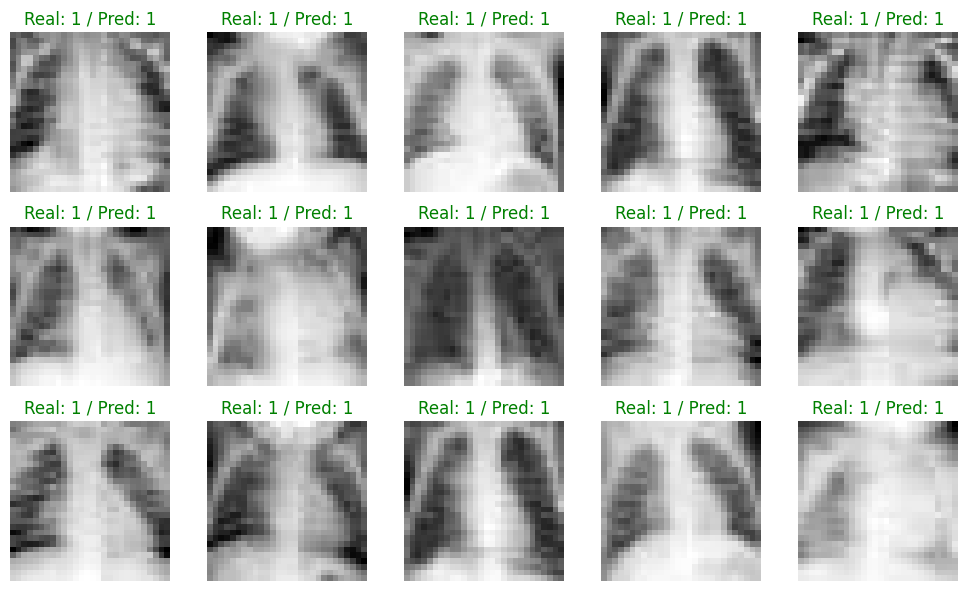

In [ ]:
import matplotlib.pyplot as plt
import random
import numpy as np

r, c = 3, 5
fig = plt.figure(figsize=(2*c, 2*r))

# 1. Máscara para obtener solo las muestras de la clase positiva (1)
positives = (y_test_bin == 1)
X_test_positives = X_test[positives]
y_test_positives = y_test_bin[positives]

for _r in range(r):
    for _c in range(c):
        plt.subplot(r, c, _r*c + _c + 1)

        # 2. Elegir un índice aleatorio de las imágenes filtradas
        ix = random.randint(0, len(X_test_positives) - 1)

        # 3. Extraer la imagen y su etiqueta usando indexación de NumPy
        img = X_test_positives[ix]
        y_true_label = y_test_positives[ix]

        # 4. Mostrar la imagen en escala de grises
        plt.imshow(img.reshape(28, 28), cmap='gray')
        plt.axis("off")

        # 5. Obtener la predicción del perceptrón para la imagen
        y_pred = evaluate(perceptron, [img])

        # 6. Colorear título según coincidencia
        plt.title(f"Real: {y_true_label} / Pred: {y_pred[0]}",
                  color="green" if y_true_label == y_pred[0] else "red")

plt.tight_layout()
plt.show()

Como puedes ver la métrica de precisión es muy útil pero puede llevar a engaños. Esto se hace especialmente patente en aplicaciones en las que tenemos muy pocas muestras de la clase que queremos capturar. Un ejemplo claro es el de detección de transacciones bancarias fraudulentas, que representan cerca del 0.001% del total de operaciones realizadas. Un modelo de clasificación binaria que siempre diese como resultado que una transacción NO es fraudulenta tendría una precisión del 99.999%, sin embargo sería un modelo totalmente inútil en el mundo real.

> ⚡ Siempre es recomendable tener unas primeras métricas `baseline` con las que comparar nuestros modelos. Estas métricas pueden obtenerse con un modelo aleatorio (antes de ser entrenado) o en el caso de la clasificación podemos utilizar directamente la distribución de clases en el dataset. Cualquier modelo que hagamos debería mejorar estas métricas.

En este caso en particular podemos obtener un mejor modelo simplemente entrenando durante más epochs (el modelo anterior no había convergido).

In [ ]:
np.random.seed(42)

# 1. Instanciar el Perceptrón con el número de características (784)
perceptron = Perceptron(X_train.shape[1])

# 2. Configurar 300 épocas y un learning rate más adecuado
epochs, lr = 300, 0.1

# 3. Entrenar el modelo de forma silenciosa (verbose=False)
perceptron.fit(X_train, y_train_bin, epochs, lr, verbose=False)

# 4. Generar las predicciones para el conjunto de test
y_pred = evaluate(perceptron, X_test)

# 5. Calcular e imprimir el Accuracy alcanzado
acc = accuracy(y_pred, y_test_bin.ravel())
print(f"Accuracy alcanzado tras 300 épocas: {acc * 100:.2f}%")

Accuracy alcanzado tras 300 épocas: 73.88%


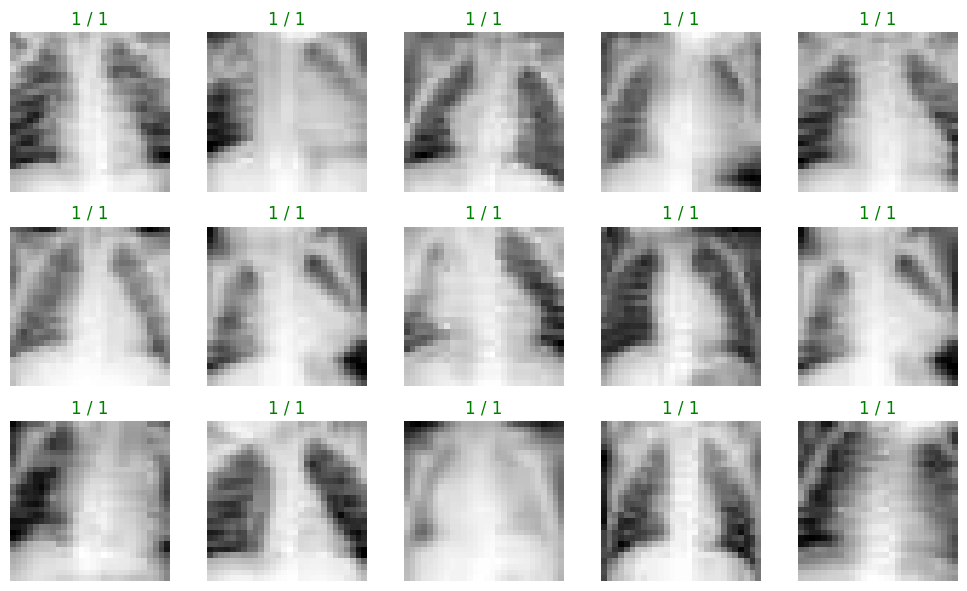

In [ ]:
r, c = 3, 5
fig = plt.figure(figsize=(2*c, 2*r))

for _r in range(r):
    for _c in range(c):
        plt.subplot(r, c, _r*c + _c + 1)

        # 1. Máscara usando tu variable y_test_bin
        positives = (y_test_bin.ravel() == 1)

        # 2. Selección de índice aleatorio
        ix = random.randint(0, len(X_test[positives]) - 1)

        # 3. Extraer imagen y etiqueta real
        img = X_test[positives][ix]
        y_true = y_test_bin.ravel()[positives][ix]

        # 4. Dibujar imagen de 28x28
        plt.imshow(img.reshape(28, 28), cmap='gray')
        plt.axis("off")

        # 5. Obtener predicción del Perceptrón
        y_preds = evaluate(perceptron, [img])

        # 6. Título con color según el resultado
        plt.title(f"{y_true} / {y_preds[0]}",
                  color="green" if y_true == y_preds[0] else "red")

plt.tight_layout()
plt.show()

Todas las métricas que vamos a ver están implementadas en la librería `Scikit Learn`, por lo que te recomiendo que las uses directamente para evitar errores en la implementación.

In [ ]:

from sklearn.metrics import accuracy_score

# Aseguramos que las etiquetas reales estén en formato 1D usando .ravel()
acc_sklearn = accuracy_score(y_test_bin.ravel(), y_pred)

print(f"Accuracy (scikit-learn): {acc_sklearn * 100:.2f}%")

Accuracy (scikit-learn): 73.88%


### La Matriz de Confusión

Una matriz de confusión nos va a indicar exactamente cuales son los puntos fuertes y débiles de nuestro clasificador. Para cada clase, vamos a calcular cuantos elementos han sido bien clasificados por nuestro modelo y cuántos han sido confundidos con otras clases (esta matriz nos será muy útil en clasificación en varias clases también).

In [ ]:
#discreta
TP = np.sum((y_pred == 1) & (y_test_5 == 1))
TN = np.sum((y_pred == 0) & (y_test_5 == 0))
FP = np.sum((y_pred == 1) & (y_test_5 == 0))
FN = np.sum((y_pred == 0) & (y_test_5 == 1))

CM = [[TN, FP],
      [FN, TP]]
CM

[[np.int64(45552), np.int64(343824)], [np.int64(0), np.int64(0)]]

En esta matriz podemos observar:
    
- Verdaderos Positivos (TP, *True Positives*): elementos que nuestro modelo clasifica correctamente como la clase que nos interesa, la clase positiva (fila 1, columna 1).
- Verdaderos Negativos (TN, *True Negatives*): elementos que nuestro modelo clasifica correctamente como la clase negativa (fila 0, columna 0).
- Falsos Positivos (FP, *False Positives*): elementos que nuestro modelo clasifica erróneamente como la clase positiva (fila 0, columna 1).
- Falsos Negativos (FN, *False Negatives*): elementos que nuestro modelo clasifica erróneamente como la clase negativa (fila 1, columna 0).

In [ ]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test_5, y_pred)

array([[ 73, 551],
       [  0,   0]])

> 💡 Una vez vistos los conceptos definidos en este apartado podemos reescribir la *accuracy* como $ accuracy = \frac{TP + TN}{TP+TN+FP+FN} $

### *Precision* y *Recall*

Hemos visto la confusión a la que nos puede llevar una métrica simple como la *accuracy*. Ahora veremos dos métricas que un poco más informativas. Éstas son *precision* (no confundir con la precisión, en castellano, equivalente a la *accuracy*) y *recall*. Para definir estas métricas primero necesitamos definir los siguiente conceptos:

$$ precision = \frac{TP}{TP+FP} $$

$$ recall = \frac{TP}{TP+FN} $$

En la siguiente imágen puedes ver una visualización de estas métricas. *Precision* nos da una idea de cómo de propenso es nuestro modelo a dar falsos positivos. Un valor cercano a $1$ indicará que nuestro modelo apenas da falsos positivos (aunque puede seguir fallando dando falsos negativos) mientras que un valor cercano a $0$ indicará que nuestro modelo da muchos falsos positivos. Lo mismo aplica al *Recall*, pero en este caso aplicada a los falsos negativos. Un valor cercano a $1$ indicará que nuestro modelo apenas da falsos negativos (aunque puede seguir fallando dando falsos positivos) mientras que un valor cercano a $0$ indicará que nuestro modelo da muchos falsos negativos.

![](https://upload.wikimedia.org/wikipedia/commons/thumb/2/26/Precisionrecall.svg/800px-Precisionrecall.svg.png)

In [ ]:
# otra manera de precision
def precision(y_pred, y):
    TP = np.sum((y_pred == 1) & (y == 1))
    FP = np.sum((y_pred == 1) & (y == 0))
    return TP / (TP + FP)

def recall(y_pred, y):
    TP = np.sum((y_pred == 1) & (y == 1))
    FN = np.sum((y_pred == 0) & (y == 1))
    return TP / (TP + FN)

In [ ]:
y_pred = evaluate(perceptron, X_test)
precision(y_pred, y_test_5), recall(y_pred, y_test_5)

/tmp/ipykernel_1719/2240466344.py:10: RuntimeWarning: invalid value encountered in scalar divide
  return TP / (TP + FN)


(np.float64(0.0), np.float64(nan))

In [ ]:
from sklearn.metrics import precision_score, recall_score

precision_score(y_test_5, y_pred), recall_score(y_test_5, y_pred)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


(0.0, 0.0)

En función de la aplicación en la que estemos trabajando vamos a querer optimizar una métrica u otra. En aplicaciones en las que tener falsos positivos sea perjudicial (por ejemplo, aplicaciones de seguridad) querremos modelos con un buena *precision*, mientras que en aplicaciones en las que tener falsos negativos sea perjudicial (por ejemplo, sistemas de diagnóstico médico) querremos modelos con buen *recall*. Una vez nuestro modelo ha sido entrenado, podemos ajustar estas métricas variando el valor del *threshold* utilizado en la evaluación. A esto se le conoce como el *precision-recall trade off*.

In [ ]:
for t in np.linspace(0.1,0.9,20):
    y_pred = evaluate(perceptron, X_test, t)
    print(f"Threshold: {t:.3f} Precision {precision(y_pred, y_test_5):.4f} Recall {recall(y_pred, y_test_5):.4f}")

Threshold: 0.100 Precision 0.0000 Recall nan
Threshold: 0.142 Precision 0.0000 Recall nan
Threshold: 0.184 Precision 0.0000 Recall nan
Threshold: 0.226 Precision 0.0000 Recall nan
Threshold: 0.268 Precision 0.0000 Recall nan
Threshold: 0.311 Precision 0.0000 Recall nan
Threshold: 0.353 Precision 0.0000 Recall nan
Threshold: 0.395 Precision 0.0000 Recall nan
Threshold: 0.437 Precision 0.0000 Recall nan
Threshold: 0.479 Precision 0.0000 Recall nan
Threshold: 0.521 Precision 0.0000 Recall nan
Threshold: 0.563 Precision 0.0000 Recall nan
Threshold: 0.605 Precision 0.0000 Recall nan
Threshold: 0.647 Precision 0.0000 Recall nan
Threshold: 0.689 Precision 0.0000 Recall nan
Threshold: 0.732 Precision 0.0000 Recall nan
Threshold: 0.774 Precision 0.0000 Recall nan
Threshold: 0.816 Precision 0.0000 Recall nan
Threshold: 0.858 Precision 0.0000 Recall nan
Threshold: 0.900 Precision 0.0000 Recall nan


/tmp/ipykernel_1719/2240466344.py:10: RuntimeWarning: invalid value encountered in scalar divide
  return TP / (TP + FN)


Cómo se puede observar, incrementar el valor de una de las métricas implica que la otra va a disminuir (es por esto que se le llama *trade-off* ya que tenemos que llegar a un compromiso). Así pues, escogeremos un valor del *threshold* que se ajusto a los criterios de diseño de nuestra aplicación en particular (en función de la cantidad de falsos positivos y falsos negativos que estemos dispuestos a asumir).

![](https://wizardforcel.gitbooks.io/scikit-and-tensorflow-workbooks-bjpcjp/pics/decision-threshold-and-precision-vs-recall.png)

### F1-Score

Una métrica rápida que nos va a decir si nuestro modelo tiene buena *precision* y *recall* es el *F1-score*.

$$  F_1 = 2 \times \frac{precision \times recall}{precision + recall} $$

Es una métrica muy usada ya que aglutina la información de ambas métricas, sin embargo va a favorecer mucho aquellos modelos con un valor similar de *precision* y *recall*, lo cual ya hemos comentado que no es siempre lo que vamos a querer.

In [ ]:
y_pred = evaluate(perceptron, X_test)

p = precision_score(y_test_5, y_pred)
r = recall_score(y_test_5, y_pred)

f1 = 2*(p*r)/(p+r)
f1

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


ZeroDivisionError: float division by zero

In [ ]:
from sklearn.metrics import f1_score

f1_score(y_test_5, y_pred)

### La curva ROC

Podemos visualizar rápidamente el comportamiento de un modelo para varios *thresholds* con la llamada curva ROC (*Receiver Operating Characteristic*). En ella representamos el ratio de verdaderos positivos (TPR) contra el ratio de falsos positivos (FPR), definidos de la siguiente manera:

$$ TPR = \frac{TP}{TP+FN} $$

$$ FPR = \frac{FP}{FP+TN} $$

In [ ]:
def evaluate2(perceptron, x):
    w = perceptron.ws[-1]
    x = np.c_[np.ones(len(x)), x]
    y = perceptron(w, x)
    return y

In [ ]:
from sklearn.metrics import roc_curve

y_pred2 = evaluate2(perceptron, X_test)
fpr, tpr, thresholds = roc_curve(y_test_5, y_pred2)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


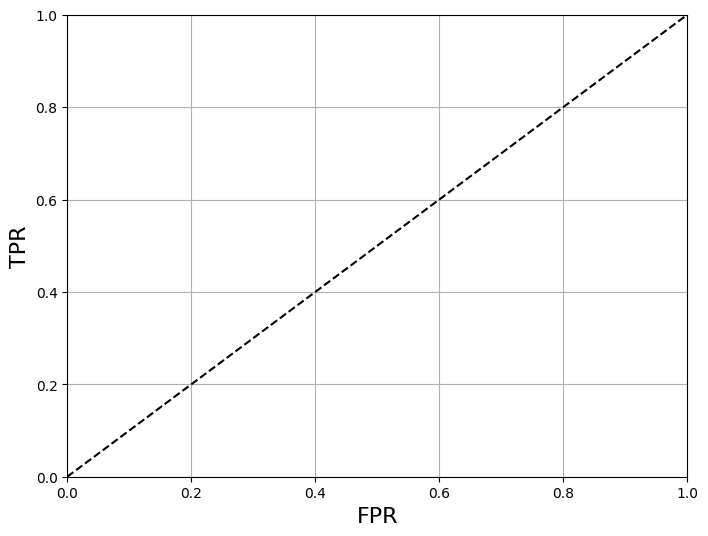

In [ ]:
def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], 'k--')
    plt.axis([0, 1, 0, 1])
    plt.xlabel('FPR', fontsize=16)
    plt.ylabel('TPR', fontsize=16)
    plt.grid(True)

plt.figure(figsize=(8, 6))
plot_roc_curve(fpr, tpr)
plt.show()

Una métrica muy utilizada para comparar clasificadores es el área bajo la curva ROC, ya que nos indica como de robusto es un modelo. La línea recta representa un modelo *naive* que podemos usar como baseline. Cómo puedes ver el área bajo la curva ROC de este modelo es de $0.5$, por lo que cualquier modelo que hagamos debería superar este valor. Cuánto más se acerque la curva a la esquina superior izquierda, mayor será el área y mejor será el modelo.

In [ ]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_test_5, y_pred2)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


nan

## Resumen

En este post hemos visto las métricas más comunes cuando trabajamos con clasificadores (tanto binarios como multi-clase). Para ello hemos trabajado con el dataset MNIST, uno de los datasets más utilizados en el `Machine Learning`. El objetivo es el de clasificar imágenes de dígitos manuscritos en 10 clases (desde el dígito 0 al 9), sin embargo lo hemos adaptado para hacer clasificación binaria de imágenes con el número 5. También hemos mejorado ligeramente la implementación de nuestro `Perceptrón` con una mejor inicialización de los pesos y la posibilidad de visualizar la evolución de la función de pérdida durante el entrenamiento. Después hemos visto las siguiente métricas:

- *Accuracy* es la más simple, consistente en contar cuantos elementos del dataset nuestro modelo clasifica correctamente. Puede llevarnos a engaños si no tenemos en cuenta la distribución de nuestras clases, poniendo en relevancia la necesidad de tener métricas `baseline` para comprar nuestros primeros modelos.
- La matriz de confusión nos va indicar el número de elementos del nuestro dataset que el modelo clasifica bien, así como todos los que confunda con otras clases. De esta manera sabremos cómo mejorar nuestro modelo.
- *Precision* y *Recall* nos indican cómo de robusto será nuestro modelo, cuantificando los falsos positivos y falsos negativos. En función de nuestra aplicación y su sensibilidad preferiremos una mejor métrica u otra (como hemos visto, mejorar una de ella implica empeorar la otra).
- El *F1-Score* nos dará una idea rápida de la robustez del modelo combinando las dos métricas anteriores.
- La curva *ROC*, y en especial el área debajo de la curva, será una muy buena manera de comparar modelos para poder elegir el que más se ajuste a nuestras necesidades.

Como podemos ver, evaluar un modelo va más allá de proporcionar un valor de precisión y dependerá en gran medida de la aplicación en cuestión y las condiciones reales a las que se vaya a enfrentar nuestro modelo en el mundo real. Monitorizar nuestros modelos constantemente nos permitirá mejorarlos de manera contínua así como encontrar posibles fallos, y para ello saber qué métricas son las importantes es fundamental.